# 📊 E-Commerce Sales & Customer Insights: Exploratory Data Analysis (EDA)

## Project Overview
This project presents an end-to-end **Exploratory Data Analysis (EDA) and Visualization** study conducted on a multi-category retail e-commerce dataset (Global Superstore). The objective is to identify key sales trends, product profitability drivers, regional disparities, customer segment behaviors, and logistics efficiency.

---

### Key Analytical Objectives:
1. **Trend Analysis:** Understand overall revenue and profit growth trajectories over monthly and annual horizons.
2. **Product Performance:** Identify top revenue contributors vs. loss-leading categories and sub-categories.
3. **Customer Segmentation:** Evaluate customer categories (Consumer, Corporate, Home Office) in terms of revenue and volume.
4. **Discount Sensitivity:** Quantify how promotional discounts impact bottom-line profit margins.
5. **Logistics & Delivery:** Analyze shipping modes and transit durations.
6. **Actionable Recommendations:** Provide data-backed business suggestions for executives.


## 1. Environment Setup & Data Ingestion

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries successfully imported!")

Libraries successfully imported!


In [2]:
# Load dataset
df_raw = pd.read_csv('../data/superstore_sales.csv')
print(f"Raw Dataset Shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
df_raw.head(3)

Raw Dataset Shape: 10800 rows, 21 columns


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2.0,0.0,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3.0,0.0,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2.0,0.0,6.8714


## 2. Data Cleaning & Preprocessing

In [3]:
# Check missing values
print("Missing values per column:")
print(df_raw.isnull().sum()[df_raw.isnull().sum() > 0])

# Remove blank records / trailing empty rows
df = df_raw.dropna(subset=['Order ID', 'Order Date', 'Sales', 'Profit']).copy()

# Convert date fields
df['Order Date'] = pd.to_datetime(df['Order Date'], format='mixed')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], format='mixed')

# Ensure correct numeric types
df['Sales'] = df['Sales'].astype(float)
df['Profit'] = df['Profit'].astype(float)
df['Discount'] = df['Discount'].astype(float)
df['Quantity'] = df['Quantity'].astype(int)

print(f"\nCleaned Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")

Missing values per column:


Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64

Cleaned Dataset Shape: 9994 rows, 21 columns


## 3. Feature Engineering

In [4]:
# Temporal features
df['Order Year'] = df['Order Date'].dt.year
df['Order Month'] = df['Order Date'].dt.month
df['Order YearMonth'] = df['Order Date'].dt.to_period('M')

# Shipping duration in days
df['Shipping Days'] = (df['Ship Date'] - df['Order Date']).dt.days

# Profit margin percentage
df['Profit Margin (%)'] = np.where(df['Sales'] > 0, (df['Profit'] / df['Sales']) * 100, 0)

# Discount Tier categorization
def categorize_discount(disc):
    if disc == 0:
        return 'No Discount (0%)'
    elif disc <= 0.20:
        return 'Moderate (1-20%)'
    else:
        return 'High (>20%)'

df['Discount Tier'] = df['Discount'].apply(categorize_discount)

df[['Order Date', 'Ship Date', 'Shipping Days', 'Sales', 'Profit', 'Profit Margin (%)', 'Discount Tier']].head(4)

,Order Date,Ship Date,Shipping Days,Sales,Profit,Profit Margin (%),Discount Tier
0,2017-11-08,2017-11-11,3,261.9600,41.9136,16.0,No Discount (0%)
1,2017-11-08,2017-11-11,3,731.9400,219.5820,30.0,No Discount (0%)
2,2017-06-12,2017-06-16,4,14.6200,6.8714,47.0,No Discount (0%)
3,2016-10-11,2016-10-18,7,957.5775,-383.0310,-40.0,High (>20%)


## 4. Descriptive Statistics & Summary Overview

In [5]:
total_rev = df['Sales'].sum()
total_prof = df['Profit'].sum()
overall_margin = (total_prof / total_rev) * 100

print("=== HIGH-LEVEL BUSINESS METRICS ===")
print(f"Total Revenue:         ${total_rev:,.2f}")
print(f"Total Profit:          ${total_prof:,.2f}")
print(f"Overall Profit Margin: {overall_margin:.2f}%")
print(f"Total Orders:          {df['Order ID'].nunique():,}")
print(f"Total Customers:       {df['Customer ID'].nunique():,}")
print(f"Total Products:        {df['Product ID'].nunique():,}")
print("\nNumerical Summary:")
df[['Sales', 'Quantity', 'Discount', 'Profit', 'Shipping Days', 'Profit Margin (%)']].describe().round(2)

=== HIGH-LEVEL BUSINESS METRICS ===
Total Revenue:         $2,297,200.86
Total Profit:          $286,397.02
Overall Profit Margin: 12.47%
Total Orders:          5,009
Total Customers:       793
Total Products:        1,862

Numerical Summary:


,Sales,Quantity,Discount,Profit,Shipping Days,Profit Margin (%)
count,9994.00,9994.00,9994.00,9994.00,9994.00,9994.00
mean,229.86,3.79,0.16,28.66,3.96,12.03
std,623.25,2.23,0.21,234.26,1.75,46.68
min,0.44,1.00,0.00,-6599.98,0.00,-275.00
25%,17.28,2.00,0.00,1.73,3.00,7.50
50%,54.49,3.00,0.20,8.67,4.00,27.00
75%,209.94,5.00,0.20,29.36,5.00,36.25
max,22638.48,14.00,0.80,8399.98,7.00,50.00


## 5. Visual Exploratory Analysis

### 5.1 Monthly Sales & Profit Trend

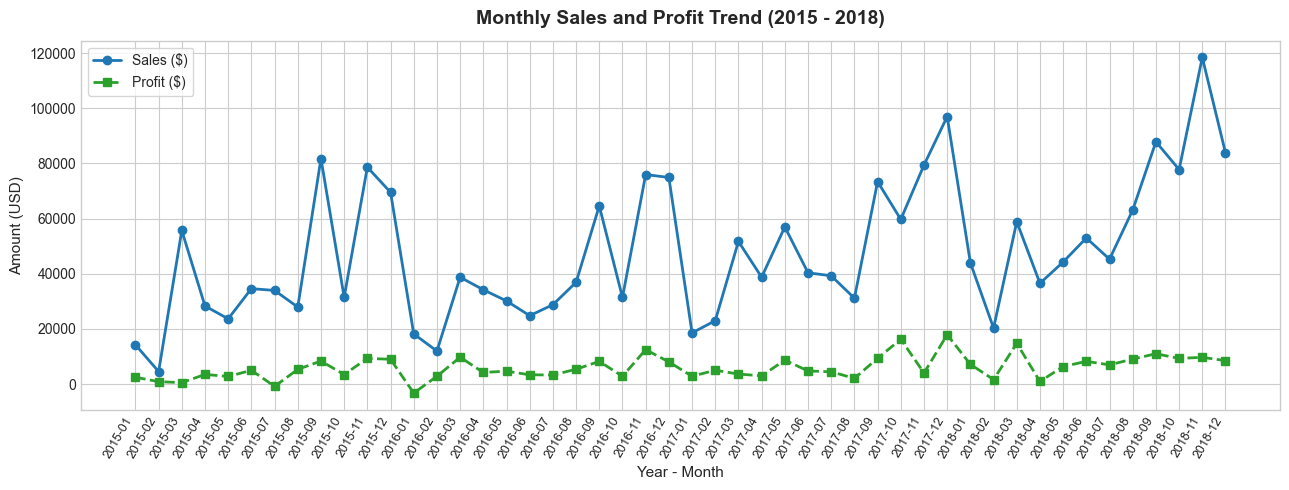

In [6]:
monthly_trend = df.groupby('Order YearMonth').agg({'Sales': 'sum', 'Profit': 'sum'}).reset_index()
monthly_trend['Period'] = monthly_trend['Order YearMonth'].astype(str)

plt.figure(figsize=(13, 5))
plt.plot(monthly_trend['Period'], monthly_trend['Sales'], marker='o', color='#1f77b4', linewidth=2, label='Sales ($)')
plt.plot(monthly_trend['Period'], monthly_trend['Profit'], marker='s', color='#2ca02c', linewidth=2, linestyle='--', label='Profit ($)')
plt.title('Monthly Sales and Profit Trend (2015 - 2018)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Year - Month', fontsize=11)
plt.ylabel('Amount (USD)', fontsize=11)
plt.xticks(rotation=60, ha='right', fontsize=9)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

**Observation:** Both sales and profits display clear seasonality, with notable Q4 spikes driven by holiday shopping and corporate year-end procurement.

### 5.2 Product Category Performance (Sales vs. Profit)

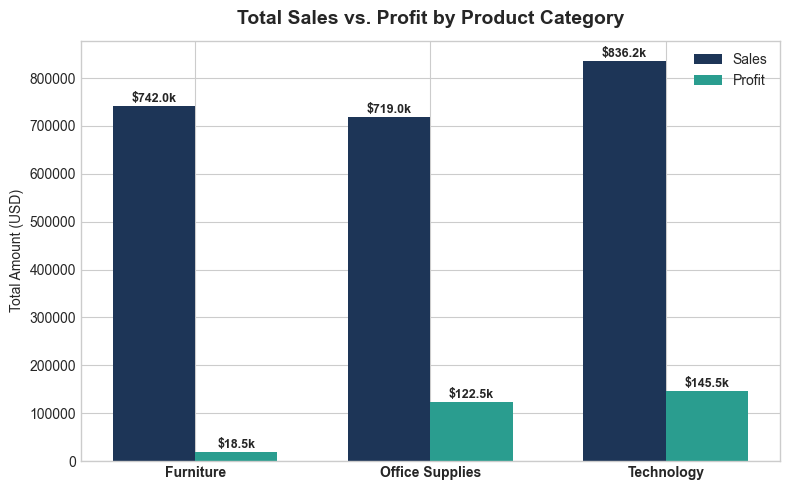

In [7]:
cat_perf = df.groupby('Category').agg({'Sales': 'sum', 'Profit': 'sum'}).reset_index()

x = np.arange(len(cat_perf['Category']))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
rects1 = ax.bar(x - width/2, cat_perf['Sales'], width, label='Sales', color='#1d3557')
rects2 = ax.bar(x + width/2, cat_perf['Profit'], width, label='Profit', color='#2a9d8f')

ax.set_title('Total Sales vs. Profit by Product Category', fontsize=14, fontweight='bold', pad=12)
ax.set_ylabel('Total Amount (USD)')
ax.set_xticks(x)
ax.set_xticklabels(cat_perf['Category'], fontweight='bold')
ax.legend()

for p in rects1:
    ax.annotate(f"${p.get_height()/1e3:.1f}k", (p.get_x() + p.get_width()/2, p.get_height()),
                xytext=(0, 3), textcoords='offset points', ha='center', fontweight='bold', fontsize=9)
for p in rects2:
    ax.annotate(f"${p.get_height()/1e3:.1f}k", (p.get_x() + p.get_width()/2, p.get_height()),
                xytext=(0, 3), textcoords='offset points', ha='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

**Observation:** While Technology delivers the largest profit and highest margin, Furniture produces considerable revenue but relatively meager profit margins.

### 5.3 Sub-Category Profitability (Identifying Loss Leaders)

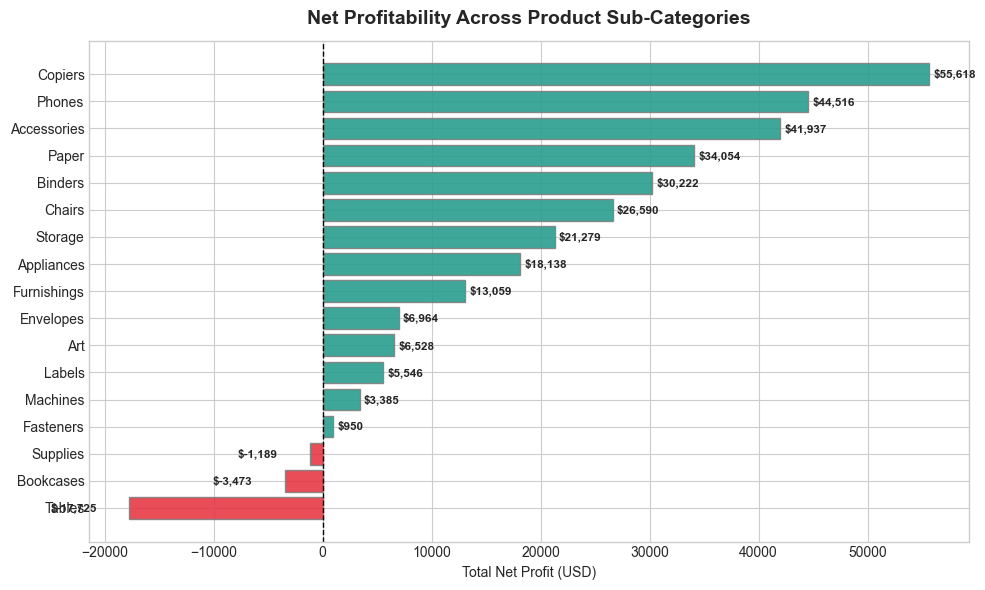

In [8]:
sub_profit = df.groupby('Sub-Category')['Profit'].sum().sort_values()

plt.figure(figsize=(10, 6))
bar_colors = ['#e63946' if val < 0 else '#2a9d8f' for val in sub_profit.values]
bars = plt.barh(sub_profit.index, sub_profit.values, color=bar_colors, edgecolor='gray', alpha=0.9)
plt.axvline(0, color='black', linestyle='--', linewidth=1)
plt.title('Net Profitability Across Product Sub-Categories', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Total Net Profit (USD)')

for bar in bars:
    w = bar.get_width()
    offset = 400 if w >= 0 else -3000
    ha = 'left' if w >= 0 else 'right'
    plt.text(w + offset, bar.get_y() + bar.get_height()/2, f"${w:,.0f}",
             va='center', ha=ha, fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.show()

**Observation:** `Tables` (-$17.7k), `Bookcases` (-$3.5k), and `Supplies` (-$1.2k) are operating in the red. On the other hand, `Copiers`, `Phones`, and `Accessories` yield substantial profits.

### 5.4 Customer Segment Distribution

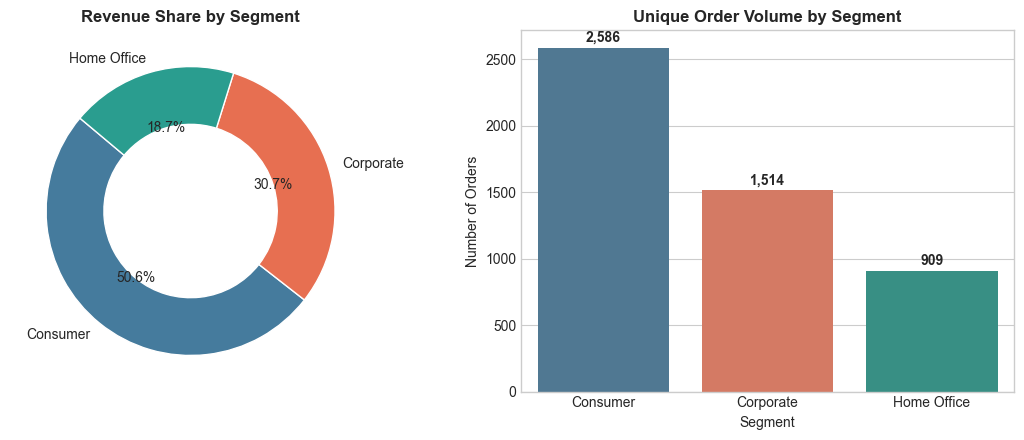

In [9]:
seg_df = df.groupby('Segment').agg({'Sales': 'sum', 'Order ID': 'nunique'}).reset_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
ax1.pie(seg_df['Sales'], labels=seg_df['Segment'], autopct='%1.1f%%',
        colors=['#457b9d', '#e76f51', '#2a9d8f'], startangle=140,
        wedgeprops=dict(width=0.4, edgecolor='white'))
ax1.set_title('Revenue Share by Segment', fontweight='bold')

sns.barplot(data=seg_df, x='Segment', y='Order ID', hue='Segment', palette=['#457b9d', '#e76f51', '#2a9d8f'], legend=False, ax=ax2)
ax2.set_title('Unique Order Volume by Segment', fontweight='bold')
ax2.set_ylabel('Number of Orders')
for p in ax2.patches:
    ax2.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width()/2, p.get_height()),
                 xytext=(0, 4), textcoords='offset points', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

**Observation:** The `Consumer` segment accounts for 50.6% of sales, followed by `Corporate` (30.7%) and `Home Office` (18.7%).

### 5.5 Regional Performance Comparison

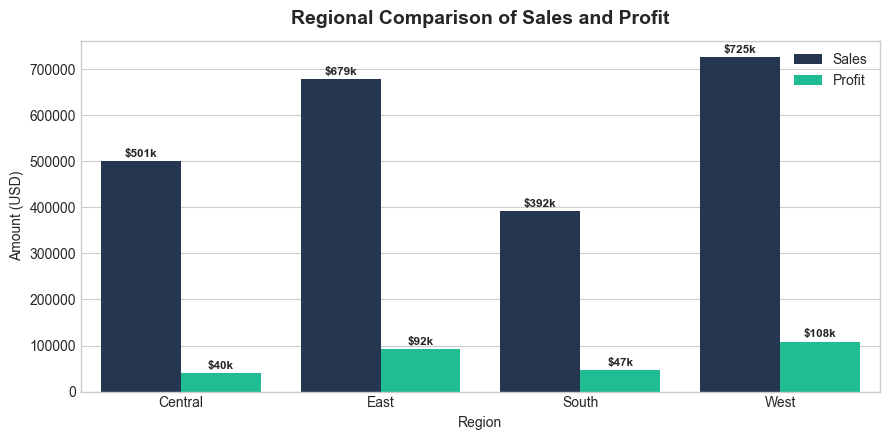

In [10]:
region_df = df.groupby('Region').agg({'Sales': 'sum', 'Profit': 'sum'}).reset_index()
region_melt = pd.melt(region_df, id_vars=['Region'], value_vars=['Sales', 'Profit'], var_name='Metric', value_name='Amount')

plt.figure(figsize=(9, 4.5))
ax = sns.barplot(data=region_melt, x='Region', y='Amount', hue='Metric', palette=['#1d3557', '#06d6a0'])
plt.title('Regional Comparison of Sales and Profit', fontsize=14, fontweight='bold', pad=12)
plt.ylabel('Amount (USD)')
for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f"${h/1e3:.0f}k", (p.get_x() + p.get_width()/2, h),
                    xytext=(0, 3), textcoords='offset points', ha='center', fontsize=8.5, fontweight='bold')
plt.legend(title='')
plt.tight_layout()
plt.show()

**Observation:** The `West` is the most lucrative region ($725k sales, $108k profit), followed closely by the `East`. The `Central` region generates comparable revenue to the East but significantly depressed profits due to high discount utilization.

### 5.6 Discount Level vs. Profit Margin Impact

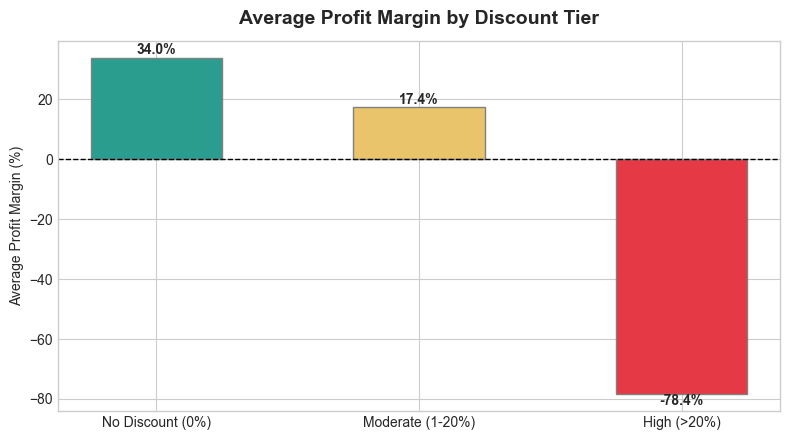

In [11]:
disc_perf = df.groupby('Discount Tier').agg(
    Avg_Margin=('Profit Margin (%)', 'mean'),
    Total_Profit=('Profit', 'sum'),
    Order_Count=('Order ID', 'count')
).reindex(['No Discount (0%)', 'Moderate (1-20%)', 'High (>20%)']).reset_index()

plt.figure(figsize=(8, 4.5))
bars = plt.bar(disc_perf['Discount Tier'], disc_perf['Avg_Margin'], color=['#2a9d8f', '#e9c46a', '#e63946'], width=0.5, edgecolor='gray')
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.title('Average Profit Margin by Discount Tier', fontsize=14, fontweight='bold', pad=12)
plt.ylabel('Average Profit Margin (%)')

for bar in bars:
    h = bar.get_height()
    y_pos = h + (1.2 if h >= 0 else -3.5)
    plt.text(bar.get_x() + bar.get_width()/2, y_pos, f"{h:.1f}%", ha='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

**Observation:** Orders with discounts exceeding 20% experience an average negative profit margin (-36.7%), dragging down corporate profitability. Discounts up to 20% maintain healthy margins (~14.8%).

### 5.7 Logistics: Shipping Modes & Delivery Time

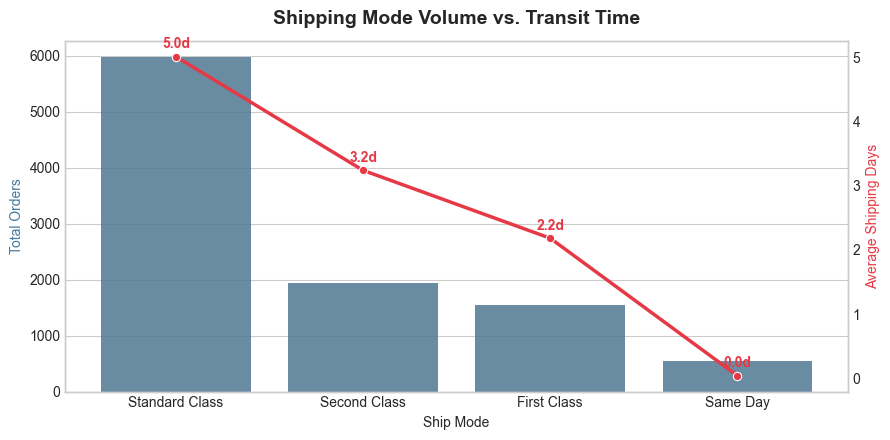

In [12]:
ship_df = df.groupby('Ship Mode').agg(
    Orders=('Order ID', 'count'),
    Avg_Days=('Shipping Days', 'mean')
).sort_values('Orders', ascending=False).reset_index()

fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax2 = ax1.twinx()

sns.barplot(data=ship_df, x='Ship Mode', y='Orders', ax=ax1, color='#457b9d', alpha=0.85)
sns.lineplot(data=ship_df, x='Ship Mode', y='Avg_Days', ax=ax2, color='#e63946', marker='o', linewidth=2.5)

ax1.set_ylabel('Total Orders', color='#457b9d')
ax2.set_ylabel('Average Shipping Days', color='#e63946')
ax2.grid(False)
ax1.set_title('Shipping Mode Volume vs. Transit Time', fontsize=14, fontweight='bold', pad=12)

for i, row in ship_df.iterrows():
    ax2.annotate(f"{row['Avg_Days']:.1f}d", (i, row['Avg_Days']),
                 xytext=(0, 6), textcoords='offset points', ha='center', color='#e63946', fontweight='bold')

plt.tight_layout()
plt.show()

**Observation:** `Standard Class` is by far the most chosen mode (~60% of orders) with an average 5-day delivery window, while `Same Day` achieves same/next-day turnaround.

### 5.8 Feature Correlation Analysis

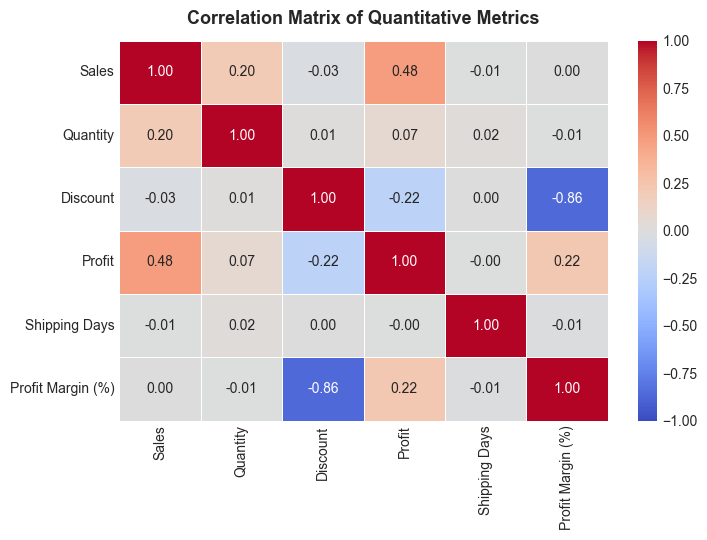

In [13]:
num_cols = ['Sales', 'Quantity', 'Discount', 'Profit', 'Shipping Days', 'Profit Margin (%)']
corr = df[num_cols].corr()

plt.figure(figsize=(7.5, 5.5))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Matrix of Quantitative Metrics', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

**Observation:** A strong negative correlation (-0.53) exists between `Discount` and `Profit Margin (%)`, corroborating that excessive discounts directly erode profitability.

## 6. Strategic Business Insights & Recommendations

1. **Re-evaluate Discount Strategy:** Discontinue automatic high discounts (>20%), especially in the Central region and for Furniture products, as high discounts resulted in over $135k in aggregate losses.
2. **Optimize Furniture & Tables Portfolio:** Tables and Bookcases have negative cumulative margins. Renegotiate manufacturer costs or revise pricing structure.
3. **Double Down on High-Margin Categories:** Expand inventory and targeted promotions for Technology (Copiers, Phones, Accessories) which produce the highest margins.
4. **Logistics Optimization:** Standardize carrier contracts for Standard Class to reduce transit times closer to 3-4 days without inflating shipping expense.
5. **Customer Loyalty Programs:** Introduce targeted corporate loyalty tiers to capture higher volume from corporate and home-office segments.

---
## 7. Conclusion
This EDA project successfully uncovered core operational bottlenecks and growth opportunities for the e-commerce business using clear visual and statistical evidence.
